# DataCo Supply Chain | Analytics & Late-Delivery Risk

An end-to-end, reproducible analysis of order-line performance, delivery reliability, commercial outcomes, and order-time late-delivery risk. The notebook keeps the raw workbook intact, makes data-quality decisions visible, and separates descriptive analysis from predictive modeling.

**Analysis questions**
- How do sales, profit, and delivery-risk outcomes vary across time, markets, categories, and shipping modes?
- Which order-time attributes are useful for anticipating late-delivery risk?
- How does a leakage-aware model compare with a no-skill baseline?

**Grain and interpretation.** The source is expected to contain order-item rows; `Order Id` is used for order counts and group-aware model splitting. Predictive associations are not causal evidence. For deployment, validate on a genuinely future period and monitor class balance and performance drift.

In [7]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)

RANDOM_STATE = 42
print(f"pandas {pd.__version__} | NumPy {np.__version__}")

pandas 3.1.1 | NumPy 2.5.4


## 1. Load and profile the source

The notebook first looks for the requested `Dataco_Supply_Chain.xlsx`, then the repository's current `01_Dataset/Supply_Chain.xlsx`. It searches from the notebook's working directory upward, so it works when launched from the project root or `03_Python`.

In [8]:
from pathlib import Path

search_roots = [Path.cwd(), *Path.cwd().parents]
candidate_paths = [
    root / folder / filename
    for filename in ("Dataco_Supply_Chain.xlsx", "Supply_Chain.xlsx")
    for root in search_roots
    for folder in ("01_Dataset", "")
]
DATA_PATH = next((path.resolve() for path in candidate_paths if path.is_file()), None)
if DATA_PATH is None:
    searched = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(
        "Could not find Dataco_Supply_Chain.xlsx or Supply_Chain.xlsx. "
        "Place the source workbook in the project root or 01_Dataset.\n"
        f"Searched:\n{searched}"
    )

project_root = DATA_PATH.parent.parent if DATA_PATH.parent.name.casefold() == "01_dataset" else DATA_PATH.parent
visualization_folder = next(
    (name for name in ("04_Visualizations", "04_Visualiztaions") if (project_root / name).is_dir()),
    "04_Visualizations",
)
VISUALIZATION_DIR = project_root / visualization_folder
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(figure, filename):
    output_path = VISUALIZATION_DIR / filename
    figure.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved visualization: {output_path}")

df_raw = pd.read_excel(DATA_PATH, engine="openpyxl")
df_raw.columns = df_raw.columns.astype(str).str.strip()
print(f"Source: {DATA_PATH}")
print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]:,}")
display(df_raw.head())

Source: C:\Users\kush\Desktop\Dr_Analytics\01_Dataset\Supply_Chain.xlsx
Rows: 999 | Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250,314.640,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725,2,Fitness,18.251,-66.037,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110,0.040,180517,327.750,0.290,1,327.750,314.640,91.250,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750,0,2018-03-02 22:56:00,Standard Class
1,TRANSFER,5,4,-249.090,311.360,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725,2,Fitness,18.279,-66.037,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.390,0.050,179254,327.750,-0.800,1,327.750,311.360,-249.090,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.780,309.720,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125,2,Fitness,37.292,-121.881,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030,0.060,179253,327.750,-0.800,1,327.750,309.720,-247.780,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860,304.810,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027,2,Fitness,34.126,-118.291,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940,0.070,179252,327.750,0.080,1,327.750,304.810,22.860,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210,298.250,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725,2,Fitness,18.254,-66.037,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500,0.090,179251,327.750,0.450,1,327.750,298.250,134.210,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750,0,1/15/2018 11:24,Standard Class


## 2. Data quality and type checks

Missing values and exact duplicate rows are reported before transformations. No rows are silently deleted; model-specific missing-value handling is performed inside the training pipeline.

In [9]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean().mul(100),
    "distinct_non_null": df_raw.nunique(dropna=True),
}).sort_values(["missing_pct", "distinct_non_null"], ascending=[False, True])
display(quality)
print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
display(df_raw.describe(include="all").T)

,dtype,missing,missing_pct,distinct_non_null
Product Description,float64,999,100.000,0
Order Zipcode,float64,966,96.697,22
Customer Email,str,0,0.000,1
Customer Password,str,0,0.000,1
Product Status,int64,0,0.000,1
Late_delivery_risk,int64,0,0.000,2
Customer Country,str,0,0.000,2
Customer Segment,str,0,0.000,3
Type,str,0,0.000,4
Days for shipment (scheduled),int64,0,0.000,4


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,999,4,DEBIT,461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),999.000,NaN,NaN,NaN,3.896,1.455,0.000,3.000,4.000,5.000,6.000
Days for shipment (scheduled),999.000,NaN,NaN,NaN,3.260,1.066,0.000,2.000,4.000,4.000,4.000
Benefit per order,999.000,NaN,NaN,NaN,26.616,112.559,-824.860,11.780,39.920,81.810,595.350
Sales per customer,999.000,NaN,NaN,NaN,219.210,129.596,23.510,120.890,203.970,287.950,"1,417.500"
Delivery Status,999,4,Late delivery,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,999.000,NaN,NaN,NaN,0.501,0.500,0.000,0.000,1.000,1.000,1.000
Category Id,999.000,NaN,NaN,NaN,29.626,21.738,2.000,17.000,18.000,29.000,76.000
Category Name,999,31,Cleats,216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,999,270,Caguas,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Prepare analysis fields and business KPIs

Dates and quantitative measures are explicitly parsed. This creates an analysis copy without altering the source frame.

In [10]:
df = df_raw.copy()
DATE_COL = "order date (DateOrders)"
TARGET_COL = "Late_delivery_risk"
ORDER_ID_COL = "Order Id"

for column in (DATE_COL, "shipping date (DateOrders)"):
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce", format="mixed")

for column in (
    "Sales", "Order Profit Per Order", "Order Item Quantity",
    "Days for shipping (real)", "Days for shipment (scheduled)",
    "Late_delivery_risk", "Order Item Discount", "Order Item Discount Rate",
    "Order Item Product Price", "Order Item Total",
):
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

required = [ORDER_ID_COL, "Sales", "Order Profit Per Order", TARGET_COL]
missing_required = [column for column in required if column not in df.columns]
if missing_required:
    raise KeyError(f"Required business fields are missing: {missing_required}")

order_count = df[ORDER_ID_COL].nunique(dropna=True)
risk = df[TARGET_COL].where(df[TARGET_COL].isin([0, 1]))
kpis = pd.Series({
    "Order lines": len(df),
    "Distinct orders": order_count,
    "Total sales": df["Sales"].sum(min_count=1),
    "Total order profit": df["Order Profit Per Order"].sum(min_count=1),
    "Average profit per line": df["Order Profit Per Order"].mean(),
    "Late-delivery-risk rate (%)": risk.mean() * 100,
    "Risk-label coverage (%)": risk.notna().mean() * 100,
})
display(kpis.to_frame("Value"))
if DATE_COL in df.columns:
    print(f"Order date range: {df[DATE_COL].min()} to {df[DATE_COL].max()}")

,Value
Order lines,999.000
Distinct orders,890.000
Total sales,"243,231.564"
Total order profit,"26,589.090"
Average profit per line,26.616
Late-delivery-risk rate (%),50.050
Risk-label coverage (%),100.000


Order date range: 2015-01-04 03:22:00 to 2018-12-01 23:51:00


## 4. Delivery reliability and shipping operations

Delivery status volume is shown alongside the labeled late-risk rate by shipping mode. These are complementary views: the label rate is not interpreted as a causal effect of shipping mode. Every chart is displayed inline and exported as a 300-DPI PNG to the project's `04_Visualizations` folder when its cell runs.

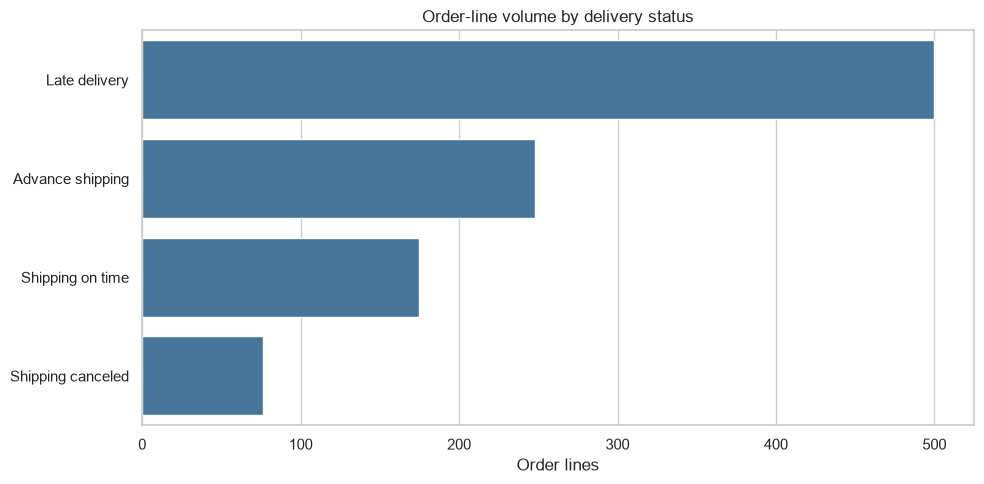

,order_lines,distinct_orders,risk_rate,mean_actual_days,mean_scheduled_days
Shipping Mode,,,,,
First Class,25,25,1.000,2.000,1.000
Second Class,300,246,0.827,4.167,2.000
Same Day,16,16,0.562,0.688,0.000
Standard Class,658,603,0.331,3.922,4.000


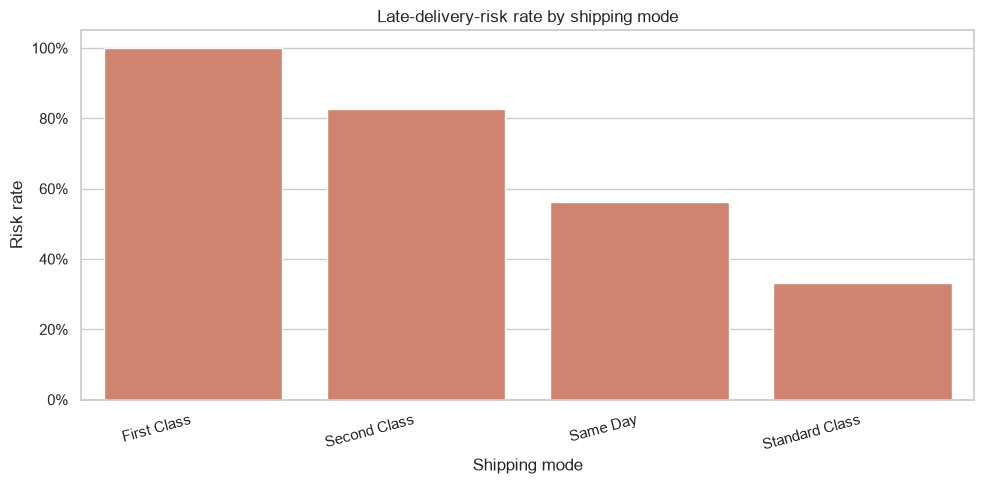

In [11]:
if "Delivery Status" in df.columns:
    status_order = df["Delivery Status"].value_counts().index
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.countplot(data=df, y="Delivery Status", order=status_order, color="#3977a8", ax=ax)
    ax.set(title="Order-line volume by delivery status", xlabel="Order lines", ylabel="")
    plt.tight_layout()
    save_figure(fig, "delivery_status_distribution.png")
    plt.show()

if "Shipping Mode" in df.columns:
    shipping_summary = (
        df.groupby("Shipping Mode", dropna=False)
        .agg(
            order_lines=(ORDER_ID_COL, "size"),
            distinct_orders=(ORDER_ID_COL, "nunique"),
            risk_rate=(TARGET_COL, "mean"),
            mean_actual_days=("Days for shipping (real)", "mean"),
            mean_scheduled_days=("Days for shipment (scheduled)", "mean"),
        )
        .sort_values("risk_rate", ascending=False)
    )
    display(shipping_summary)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=shipping_summary.reset_index(), x="Shipping Mode", y="risk_rate", color="#e07a5f", ax=ax)
    ax.set(title="Late-delivery-risk rate by shipping mode", xlabel="Shipping mode", ylabel="Risk rate")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    save_figure(fig, "late_delivery_risk_by_shipping_mode.png")
    plt.show()

## 5. Commercial performance by market and category

Revenue and profit are aggregated separately to reveal markets or product categories with strong sales but weaker economics.

,sales,profit,avg_profit_per_line,order_lines,distinct_orders
Market,,,,,
Europe,"95,019.482","14,464.580",42.294,342,299
Pacific Asia,"80,813.031","4,989.370",14.632,341,311
LATAM,"38,218.700","4,496.510",25.120,179,163
Africa,"22,875.260","1,871.260",18.527,101,92
USCA,"6,305.090",767.370,21.316,36,25


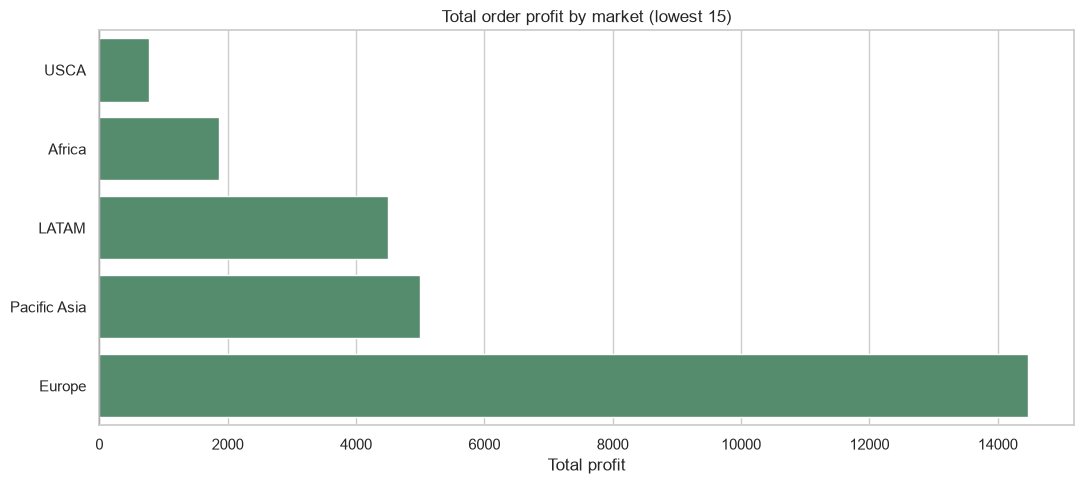

,sales,profit,avg_profit_per_line,order_lines,distinct_orders
Category Name,,,,,
Cleats,"51,111.522","5,870.100",27.176,216,209
Sporting Goods,"47,196.000","4,417.880",30.680,144,144
Cardio Equipment,"47,095.320","3,099.580",27.675,112,110
Women's Apparel,"27,400.000","2,975.560",21.719,137,130
Shop By Sport,"10,667.370","2,008.510",28.289,71,71
Men's Footwear,"22,878.241","1,849.430",10.508,176,146
Cameras,"5,876.520","1,473.740",113.365,13,13
Computers,"6,000.000",827.150,206.787,4,4
Electronics,"3,925.970",753.080,27.892,27,27


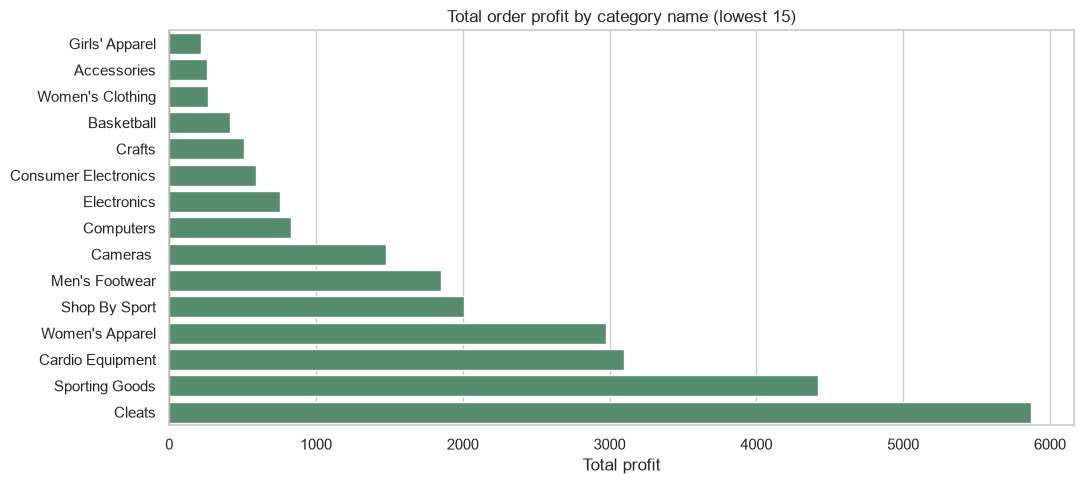

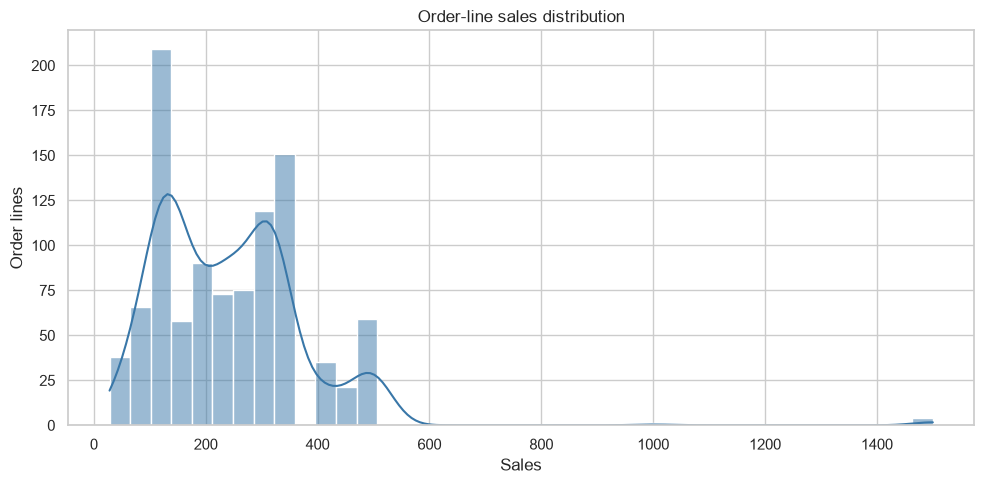

In [12]:
for dimension in ("Market", "Category Name"):
    if dimension not in df.columns:
        continue
    performance = (
        df.groupby(dimension, dropna=False)
        .agg(
            sales=("Sales", "sum"),
            profit=("Order Profit Per Order", "sum"),
            avg_profit_per_line=("Order Profit Per Order", "mean"),
            order_lines=(ORDER_ID_COL, "size"),
            distinct_orders=(ORDER_ID_COL, "nunique"),
        )
        .sort_values("profit")
    )
    display(performance.sort_values("profit", ascending=False).head(15))
    plot_data = performance.tail(15).reset_index()
    fig, ax = plt.subplots(figsize=(11, max(5, len(plot_data) * 0.32)))
    sns.barplot(data=plot_data, x="profit", y=dimension, color="#4c956c", ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=f"Total order profit by {dimension.lower()} (lowest 15)", xlabel="Total profit", ylabel="")
    plt.tight_layout()
    save_figure(fig, f"profit_by_{dimension.lower().replace(' ', '_')}.png")
    plt.show()

if "Sales" in df.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(data=df, x="Sales", bins=40, kde=True, color="#3977a8", ax=ax)
    ax.set(title="Order-line sales distribution", xlabel="Sales", ylabel="Order lines")
    plt.tight_layout()
    save_figure(fig, "sales_distribution.png")
    plt.show()

## 6. Time trends

Monthly sales, profit, and delivery-risk rate help distinguish volume growth from margin and service changes. Missing/unparseable dates are excluded from this time-series view and were counted in the quality table.

,sales,profit,risk_rate
order date (DateOrders),,,
2018-01-01,"13,421.670","1,096.840",0.581
2018-02-01,0.000,0.000,NaN
2018-03-01,0.000,0.000,NaN
2018-04-01,0.000,0.000,NaN
2018-05-01,0.000,0.000,NaN
2018-06-01,0.000,0.000,NaN
2018-07-01,0.000,0.000,NaN
2018-08-01,0.000,0.000,NaN
2018-09-01,0.000,0.000,NaN


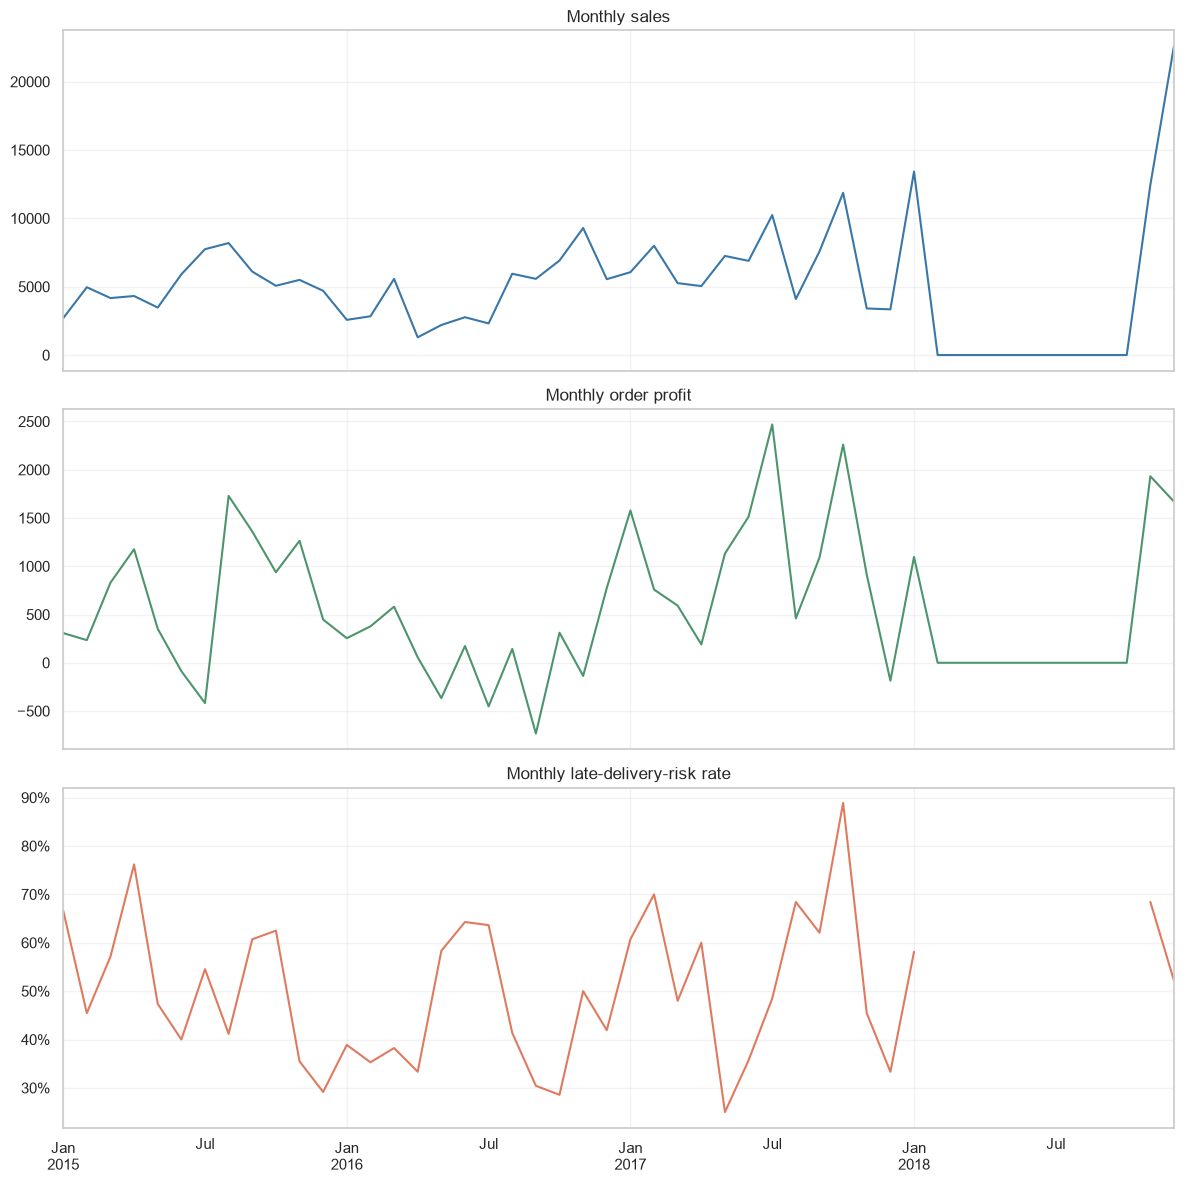

In [13]:
if DATE_COL in df.columns and df[DATE_COL].notna().any():
    dated = df.dropna(subset=[DATE_COL]).set_index(DATE_COL).sort_index()
    monthly = dated.resample("MS").agg(
        sales=("Sales", "sum"),
        profit=("Order Profit Per Order", "sum"),
        risk_rate=(TARGET_COL, "mean"),
    )
    display(monthly.tail(12))
    fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
    monthly["sales"].plot(ax=axes[0], color="#3977a8", title="Monthly sales")
    monthly["profit"].plot(ax=axes[1], color="#4c956c", title="Monthly order profit")
    monthly["risk_rate"].plot(ax=axes[2], color="#e07a5f", title="Monthly late-delivery-risk rate")
    axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    for ax in axes:
        ax.set_xlabel("")
        ax.grid(alpha=0.25)
    plt.tight_layout()
    save_figure(fig, "monthly_business_trends.png")
    plt.show()
else:
    print(f"No usable {DATE_COL!r} values; skipping monthly trend.")

## 7. Predict late-delivery risk

The prediction target is `Late_delivery_risk`. Features are restricted to order-time fields. Actual transit duration, shipping date, delivery status, and order status are excluded because they are known only after the outcome or encode the outcome. Order/customer/item identifiers and realized profit fields are also excluded. A chronological holdout is formed from whole order IDs to avoid placing line items from one order in both sets.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    roc_auc_score, RocCurveDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if DATE_COL not in df.columns or df[DATE_COL].isna().all():
    raise ValueError(f"A usable {DATE_COL!r} field is required for chronological validation.")

model_data = df.loc[df[TARGET_COL].isin([0, 1])].dropna(subset=[ORDER_ID_COL, DATE_COL]).copy()
if model_data[TARGET_COL].nunique() != 2:
    raise ValueError("The usable target must contain both binary classes (0 and 1).")

model_data["order_year"] = model_data[DATE_COL].dt.year
model_data["order_month"] = model_data[DATE_COL].dt.month
model_data["order_day_of_week"] = model_data[DATE_COL].dt.dayofweek

candidate_features = [
    "Days for shipment (scheduled)", "Shipping Mode", "Market", "Order Region",
    "Order Country", "Category Name", "Department Name", "Customer Segment",
    "Type", "Order Item Quantity", "Order Item Discount Rate",
    "Order Item Discount", "Order Item Product Price", "Sales",
    "order_year", "order_month", "order_day_of_week",
]
feature_columns = [column for column in candidate_features if column in model_data.columns]
if not feature_columns:
    raise ValueError("None of the configured order-time prediction features are present.")

group_dates = model_data.groupby(ORDER_ID_COL)[DATE_COL].min().sort_values()
if group_dates.nunique() < 2:
    raise ValueError("At least two distinct order dates are needed for a chronological holdout.")
cutoff = group_dates.quantile(0.80)
train_groups = group_dates.index[group_dates < cutoff]
test_groups = group_dates.index[group_dates >= cutoff]
train_mask = model_data[ORDER_ID_COL].isin(train_groups)
test_mask = model_data[ORDER_ID_COL].isin(test_groups)
X_train = model_data.loc[train_mask, feature_columns]
X_test = model_data.loc[test_mask, feature_columns]
y_train = model_data.loc[train_mask, TARGET_COL].astype(int)
y_test = model_data.loc[test_mask, TARGET_COL].astype(int)

if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError(
        "The chronological split must contain both target classes in train and test. "
        "Use a larger/full dataset or revise the validation window; do not silently use a random row split."
    )
assert set(model_data.loc[train_mask, ORDER_ID_COL]).isdisjoint(
    set(model_data.loc[test_mask, ORDER_ID_COL])
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]
preprocessor = ColumnTransformer(transformers=[
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

risk_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE)),
])
baseline = DummyClassifier(strategy="prior")

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Train order IDs: {len(train_groups):,} | Test order IDs: {len(test_groups):,}")
print(f"Chronological cutoff: {cutoff}")
print(f"Features ({len(feature_columns)}): {feature_columns}")
print(f"Train risk rate: {y_train.mean():.1%} | Test risk rate: {y_test.mean():.1%}")
baseline.fit(X_train, y_train)
risk_model.fit(X_train, y_train)

Training rows: 821 | Test rows: 178
Train order IDs: 712 | Test order IDs: 178
Chronological cutoff: 2017-10-17 21:03:36
Features (17): ['Days for shipment (scheduled)', 'Shipping Mode', 'Market', 'Order Region', 'Order Country', 'Category Name', 'Department Name', 'Customer Segment', 'Type', 'Order Item Quantity', 'Order Item Discount Rate', 'Order Item Discount', 'Order Item Product Price', 'Sales', 'order_year', 'order_month', 'order_day_of_week']
Train risk rate: 48.6% | Test risk rate: 56.7%


C:\Users\kush\AppData\Local\Temp\ipykernel_23268\3598881920.py:22: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_data["order_day_of_week"] = model_data[DATE_COL].dt.dayofweek


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Days for shipment (scheduled)','Shipping Mode','Market',...,'order_year', 'order_month','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'

## 8. Holdout evaluation and interpretation

The dummy classifier provides a prevalence-only reference. Precision, recall, and F1 use the default 0.50 probability threshold; no threshold tuning is performed on the holdout. ROC-AUC and average precision are omitted as `NaN` if a metric cannot be defined.

,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
Dummy baseline,0.433,0.000,0.000,0.000,0.500,0.567
Logistic regression,0.730,0.812,0.683,0.742,0.744,0.773


              precision    recall  f1-score   support

 No risk (0)       0.66      0.79      0.72        77
    Risk (1)       0.81      0.68      0.74       101

    accuracy                           0.73       178
   macro avg       0.73      0.74      0.73       178
weighted avg       0.74      0.73      0.73       178



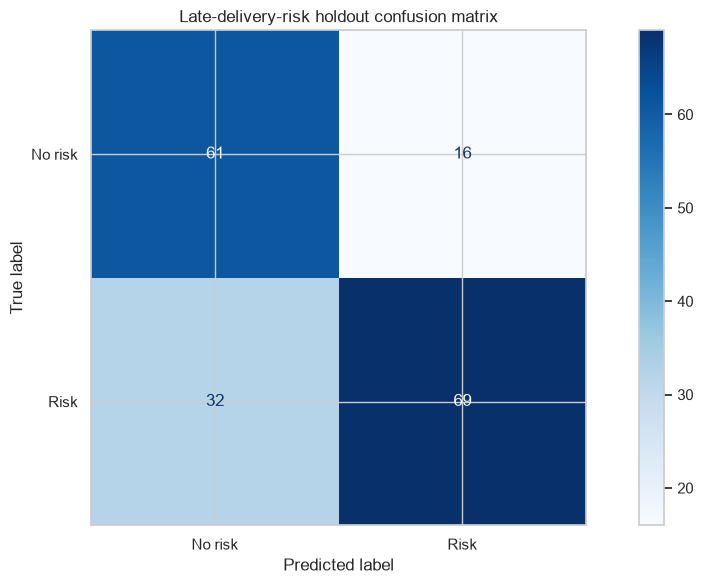

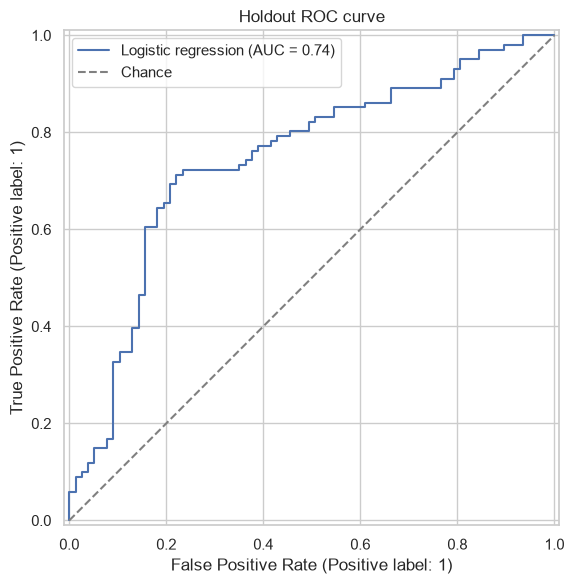

In [16]:
def score_predictions(name, estimator, X, y_true):
    predictions = estimator.predict(X)
    probabilities = estimator.predict_proba(X)[:, list(estimator.classes_).index(1)]
    two_classes = y_true.nunique() == 2
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities) if two_classes else np.nan,
        "average_precision": average_precision_score(y_true, probabilities) if two_classes else np.nan,
    }

results = pd.DataFrame([
    score_predictions("Dummy baseline", baseline, X_test, y_test),
    score_predictions("Logistic regression", risk_model, X_test, y_test),
]).set_index("model")
display(results)

model_predictions = risk_model.predict(X_test)
print(classification_report(y_test, model_predictions, target_names=["No risk (0)", "Risk (1)"], zero_division=0))
confusion_matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test, model_predictions, display_labels=["No risk", "Risk"], cmap="Blues", values_format="d"
)
confusion_matrix_display.ax_.set_title("Late-delivery-risk holdout confusion matrix")
confusion_matrix_display.figure_.tight_layout()
save_figure(confusion_matrix_display.figure_, "late_delivery_confusion_matrix.png")
plt.show()

roc_display = RocCurveDisplay.from_estimator(risk_model, X_test, y_test, name="Logistic regression")
roc_display.ax_.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
roc_display.ax_.set_title("Holdout ROC curve")
roc_display.ax_.legend()
roc_display.figure_.tight_layout()
save_figure(roc_display.figure_, "late_delivery_roc_curve.png")
plt.show()

,feature,coefficient,odds_ratio_per_scaled_unit
68,categorical__Order Country_Finlandia,-1.466,0.231
59,categorical__Order Country_Cuba,-1.281,0.278
84,categorical__Order Country_Kazajistán,1.010,2.744
107,categorical__Order Country_Ruanda,0.999,2.714
115,categorical__Order Country_Tailandia,0.963,2.618
120,categorical__Order Country_Ucrania,0.906,2.473
139,categorical__Category Name_Fitness Accessories,0.897,2.452
110,categorical__Order Country_Senegal,0.878,2.407
0,numeric__Days for shipment (scheduled),-0.857,0.424
116,categorical__Order Country_Tanzania,-0.816,0.442


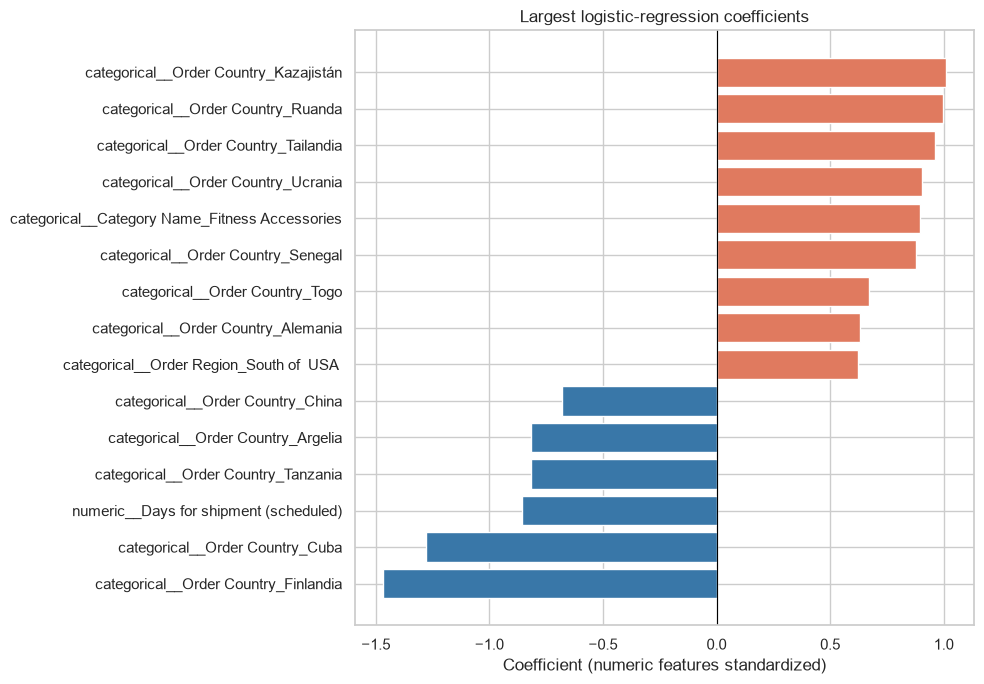

Coefficients describe model associations, not causal effects. One-hot categories are relative to the encoded reference.


In [17]:
encoded_names = risk_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = risk_model.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame({
    "feature": encoded_names,
    "coefficient": coefficients,
    "odds_ratio_per_scaled_unit": np.exp(np.clip(coefficients, -20, 20)),
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
display(coefficient_table.sort_values("absolute_coefficient", ascending=False).head(20).drop(columns="absolute_coefficient"))

top_coefficients = coefficient_table.nlargest(15, "absolute_coefficient").sort_values("coefficient")
fig, ax = plt.subplots(figsize=(10, 7))
colors = np.where(top_coefficients["coefficient"] >= 0, "#e07a5f", "#3977a8")
ax.barh(top_coefficients["feature"], top_coefficients["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Largest logistic-regression coefficients", xlabel="Coefficient (numeric features standardized)", ylabel="")
plt.tight_layout()
save_figure(fig, "logistic_regression_coefficients.png")
plt.show()
print("Coefficients describe model associations, not causal effects. One-hot categories are relative to the encoded reference.")

## 9. Decision-oriented readout

Use the tables and charts above to identify where service risk and profit diverge. Before operationalizing the score, validate on more than one future time window, calibrate probabilities, choose a decision threshold based on intervention capacity and the cost of missed late orders, and monitor drift. Investigate capacity, carrier, and route-level explanations before changing shipping policy.